# Gradient boosting: CatBoost (issue #13)

Follows the shared evaluation protocol (`src/common.py`, issue #8): development data = train + val, repeated stratified 5-fold CV x 3, seed 42, test set untouched.

Tuned scores use **nested CV** (the hyper-parameter search runs only inside each outer training fold), so they are not inflated by tuning. Same method as `boosting_sklearn.ipynb` (#10), `boosting_lightgbm.ipynb` (#12) and `boosting_xgboost.ipynb` (#11).

Early stopping: the shared `evaluate()` has no validation hook, so early stopping is shown on the official train/val split (section 3) and used to sanity-check the tuned `iterations`; it is never run on the test set.

CatBoost is configured with `allow_writing_files=False` so it does not create `catboost_info/` folders. Needs CatBoost: `pip install catboost`.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from scipy.stats import loguniform, randint
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate

from src.common import (load_dev, load_train_val, evaluate, get_cv, log_result, _who,
                        SCORING, RANDOM_STATE, ROOT)
warnings.filterwarnings('ignore')

X, y = load_dev()
# thread_count=1 inside each model: folds already run in parallel, and this keeps fit times comparable
BASE = dict(random_seed=RANDOM_STATE, thread_count=1, verbose=0, allow_writing_files=False)
print(X.shape)

(16604, 6)


## 1. Default settings (logged)

In [2]:
default = evaluate(CatBoostClassifier(**BASE), X, y, name='CatBoost', params={'defaults': True}, n_jobs=-1,
                   notes='fit time measured with thread_count=1 per model')
cols = ['model', 'cv_auc_mean', 'cv_auc_std', 'cv_pr_auc_mean', 'cv_f1_mean', 'cv_recall_mean', 'cv_precision_mean', 'fit_time_mean_s']
pd.DataFrame([default])[cols]

,model,cv_auc_mean,cv_auc_std,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,fit_time_mean_s
0,CatBoost,0.6915,0.0086,0.7928,0.7555,0.828,0.6946,2.498


## 2. Tuning with nested CV

`RandomizedSearchCV`, 20 settings, inner 3-fold CV on each outer training part, scored by ROC AUC. Searched: `iterations`, `learning_rate`, `depth`, `l2_leaf_reg`, `border_count`. (20 instead of 25 settings because CatBoost fits are the slowest of the four libraries.)

In [3]:
SPACE = {'iterations': randint(100, 501), 'learning_rate': loguniform(0.01, 0.2),
         'depth': randint(2, 8), 'l2_leaf_reg': loguniform(1, 20),
         'border_count': randint(32, 255)}
N_ITER, INNER_CV = 20, StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def make_search(seed=RANDOM_STATE):
    return RandomizedSearchCV(CatBoostClassifier(**BASE), SPACE, n_iter=N_ITER, cv=INNER_CV, scoring='roc_auc',
                              random_state=seed, n_jobs=1, refit=True)

t = time.time()
res = cross_validate(make_search(), X, y, cv=get_cv(), scoring=SCORING, n_jobs=-1)
tuned = {'date': date.today().isoformat(), 'who': _who(), 'model': 'CatBoost tuned', 'features': 'raw',
         'params': f'RandomizedSearchCV n_iter={N_ITER}', 'n_rows': len(X),
         'fit_time_mean_s': round(float(np.mean(res['fit_time'])), 1),
         'notes': 'NESTED CV (search inside each outer training fold); fit time includes the search'}
for k in SCORING:
    tuned[f'cv_{k}_mean'] = round(float(np.mean(res[f'test_{k}'])), 4)
    tuned[f'cv_{k}_std'] = round(float(np.std(res[f'test_{k}'])), 4)
log_result(tuned)

best_search = make_search().fit(X, y)
best_params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in best_search.best_params_.items()}
(ROOT / 'results' / 'best_params_catboost.json').write_text(json.dumps(best_params, indent=2))
print(f'nested AUC {tuned["cv_auc_mean"]} +/- {tuned["cv_auc_std"]} ({time.time()-t:.0f}s)')
print('final params:', best_params)

nested AUC 0.703 +/- 0.0085 (56s)
final params: {'border_count': 95, 'depth': 2, 'iterations': 230, 'l2_leaf_reg': 13.146443027030747, 'learning_rate': 0.0767539109585377}


## 3. Early stopping and overfitting check

Train on the official `train` split, early-stop on `val` (never on test). Shows how many rounds the validation AUC wants versus the tuned `iterations`.

early-stopped at round 50 | val AUC 0.7085 | tuned iterations 230


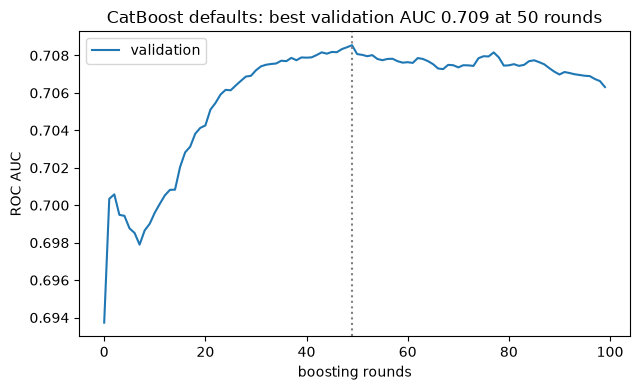

In [4]:
X_tr, y_tr, X_va, y_va = load_train_val()
m = CatBoostClassifier(iterations=600, eval_metric='AUC', early_stopping_rounds=50, **BASE).fit(
    X_tr, y_tr, eval_set=(X_va, y_va))
best_it = m.get_best_iteration()
va = m.get_evals_result()['validation']['AUC']
print('early-stopped at round', best_it + 1, '| val AUC', round(max(va), 4),
      '| tuned iterations', best_params['iterations'])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(va, label='validation')
ax.axvline(best_it, ls=':', c='gray')
ax.set_title(f'CatBoost defaults: best validation AUC {max(va):.3f} at {best_it+1} rounds')
ax.set_xlabel('boosting rounds'); ax.set_ylabel('ROC AUC'); ax.legend()
(ROOT / 'reports' / 'figures').mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(ROOT / 'reports' / 'figures' / 'boosting_catboost_overfit.png', dpi=130); plt.show()

## 4. Feature importance of the tuned model

CatBoost's default importance (PredictionValuesChange), share of total. Indicative only; permutation importance and SHAP are in #16.

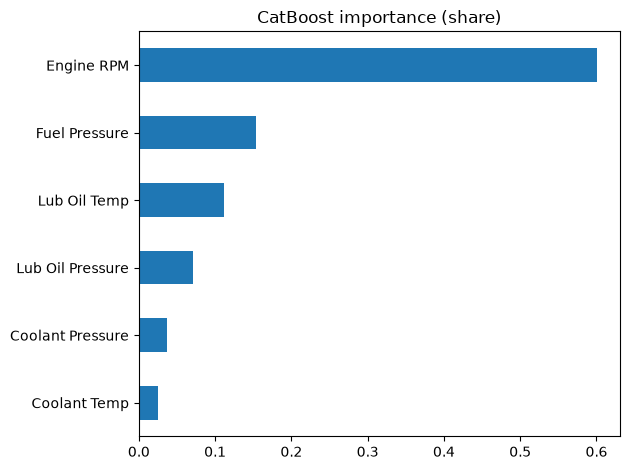

In [5]:
final = CatBoostClassifier(**BASE, **best_params).fit(X, y)
imp = pd.Series(final.get_feature_importance(), index=X.columns).sort_values()
(imp / imp.sum()).plot.barh(title='CatBoost importance (share)'); plt.tight_layout(); plt.show()